# Deep Network Developments, Coding test - Variant A (21 April 2026)

**In the Coding test, you need to train and evaluate a simple Multi-layer Perceptron (MLP) neural network on a binary classification task using the PyTorch library.**

The Coding test consists of several subtasks (A - I) that build on one another. The assignment includes an automatic testing script that checks the correctness of your solutions for the individual subtasks. Therefore, **do not modify the structure of the notebook**, do not split it into separate parts, and do not alter the already written sections; only enter your solutions in the designated places, otherwise we will not be able to evaluate your work. Your solutions must be written between the `# Implement your solution BELOW` and `# Implement your solution ABOVE` lines. If the message "Tester: .... OK" appears when running a solved subtask, the testing script did not find an error in your solution. However, the tester is not exhaustive, so it may fail to detect certain kinds of mistakes.

**Classification accuracy achievable in this task:** With a correct solution, approximately 75-85% (binary) accuracy can be achieved. (The label categories will be roughly balanced.) If the best result your neural network can achieve on the test set is significantly worse or significantly better than this, that may indicate an error and you should try to identify it. For example, you can compare the results of the subtasks with the task descriptions and with the original CSV dataset files.

**Submitting the completed assignment:** Only the notebook file (`.ipynb`) containing your final solution must be uploaded to Canvas, on the submission page for the "Coding test (21 April 2026)" assignemnt. No other files should be uploaded.  
**Please do not modify the notebook structure and do not split it into separate tasks.**

**Available time:** 180 minutes

**Grading:** A maximum of 30 points can be earned. See the points available for each individual subtask in the task descriptions.

**Constraint:** Whenever possible, we expect efficient, vectorized solutions. A loop with a large number of iterations (50+) or similarly inefficient constructs in the code may result in point deductions. The following do **not** count as vectorized solutions: recursion, list/set/dict comprehensions, iterators, generators, `map()`, `np.apply_along_axis()`, `np.vectorize()`, `np.frompyfunc()`, and similar approaches.

Exceptions where longer loops may be used without penalty:
- In task A).
- In task B), for condition "Base task" only.
- During network training, inside the training/validation/test loop, whether iterating over epochs or batches.


---

Loading the tester script and other imports.

In [1]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

from dndmsc26spring_zh1a_tester import Tester

## **A**: Loading the datasets - 1 point

**Information about the datasets:**  
We will work with two synthetic datasets (`orangejuice1_dnd26spring_zh_a.csv`, `orangejuice2_dnd26spring_zh_a.csv`) that contain the chemical properties of different types of orange juice, as well as the subjective tasting-based ratings (1-9) given by three orange-juice experts. Each row of a dataset contains the data for one type of orange juice, while the columns describe the individual chemical properties. The last three columns (named `score1`, `score2`, `score3` in the header) contain the scores given by the three experts in both files.

In the Coding test, we will first **merge the two databases containing orange juice data to obtain a larger dataset**, then **define two quality categories ("budget" / "premium" orange juices), assign all of the juices into one of these two categories based on the experts' scores, and then learn to predict this category label from the chemical properties of the juices using a neural network.**

The testing script loads the orange juice datasets stored in text form and places their contents into the strings `content1` and `content2`. Below, we print their lengths and the first 500 characters of each string. Each row of the dataset files specifies the values of the variables for one data point (one orange juice). Within a row, the values corresponding to the variables are separated by semicolons. The first row of each dataset string contains the variable names.

Your task is to **convert the strings `content1` and `content2` into NumPy arrays containing the values of the dataset variables.** The arrays must have data type `np.float32` (floating point). Place the variable values read from `content1` into the array `dataset1` with shape `(n_orangejuice1, n_variables)`, and place the variable values read from `content2` into the array `dataset2` with shape `(n_orangejuice2, n_variables)`. The shapes of the two datasets will not be the same, because they contain different numbers of data points (orange juices).


In [2]:
tester = Tester()
content1, content2 = tester.get_dataset_contents()

print("First orange juice dataset:")
print("Number of characters:", len(content1))
print(content1[:500])

print("\n\nSecond orange juice dataset:")
print("Number of characters:", len(content2))
print(content2[:500])


First orange juice dataset:
Number of characters: 135957
"dissolved solids";"pH";"titratable acidity";"electrical conductivity";"flavonoids";"aldehydes";"alcohols";"esters";"ketones";"terpenoids";"hydrocarbons";"score1";"score2";"score3"
10.306;3.646;8.347;2.225;141.74;0.869;2.007;0.903;0.028;30.566;27.76;4;6;4
9.474;3.523;10.804;1.597;168.442;0.794;1.494;1.254;0.012;50.654;0.;5;2;3
11.312;3.433;11.410;1.738;153.818;0.825;1.704;0.433;0.028;1.321;49.778;4;1;4
12.055;3.606;9.266;2.041;256.413;0.856;1.562;0.071;0.033;10.979;4.958;8;8;8
7.172;3.449;12.158


Second orange juice dataset:
Number of characters: 64982
"pH";"electrical conductivity";"titratable acidity";"dissolved solids";"flavonoids";"aldehydes";"alcohols";"esters";"ketones";"terpenoids";"hydrocarbons";"score1";"score2";"score3"
3.366;1.276;6.011;7.405;211.552;0.831;1.396;1.009;0.01;0.;15.751;3;5;4
3.68;1.968;8.711;10.358;142.338;0.871;1.651;0.513;0.029;34.032;5.485;5;4;3
3.772;1.836;4.963;6.544;205.896;0.714;1.511;0.418;0.050;

In [3]:
# implement your solution BELOW

def load_and_clean(content):
    lines = content.split("\n")

    result = []
    
    # SKIP THE HEADER
    for line in lines[1:]:
        valid_line = []
        
        # IF THE LINE IS NOT EMPTY
        if line == "":
            continue
        else:
            elements = line.split(";")

            for element in elements:
                if element == "":
                    valid_line.append(np.nan)
                else:
                    valid_line.append(float(element))
                    
        result.append(valid_line)

    res = np.array(result, dtype=np.float32)
    
    return res
    #return np.array(result, dtype=np.float32)

dataset1 = load_and_clean(content1)
dataset2 = load_and_clean(content2)

print(dataset1.shape)
print(dataset2.shape)

# implement your solution ABOVE

tester.test('dataset_load', dataset1, dataset2)

(1832, 14)
(874, 14)
Tester: Dataset loading OK


## **B**: Merging the datasets - up to a total of 6 points

Although the two orange-juice datasets contain the same variables (columns), the column order is different, unfortunately. We still want to merge them so that we can train our neural network on a larger amount of data at once.

### Base task - 2 points

In this task, you need to **create the NumPy array `dataset`, which first lists the orange juices (rows) from `dataset1`, followed by the orange juices from `dataset2`.** The number of columns in `dataset` must match the number of columns in the two original arrays. However, because the column order differs, before merging the two arrays you **must reorder the columns of the data originating from `dataset2` so that they match the column order of `dataset1`, and then place them into `dataset` in that order.** In other words, the column order in `dataset` must match the column order of `dataset1`. The arrays `dataset1` and `dataset2` no longer contain the column names, since they are simple numeric arrays, but the first row of the original CSV files specifies the column names, and they are also provided in the next cell in the lists `ATTR_NAMES1` and `ATTR_NAMES2`. You can also use these to perform the column reordering. The data type of `dataset` must match the data type of the other two arrays.

### Extra condition \#1 - 1 point

Do not use hard-coded indices for the reordering. Implement the reordering so that it works for an arbitrary permutation of the columns, only based on the contents of the lists `ATTR_NAMES1` and `ATTR_NAMES2`.

### Extra condition \#2 - 1 point

Use only vectorized NumPy operations in your code!

### Extra condition \#3 (hard) - 2 points

Your solution should satisfy both **Extra condition \#1** and **Extra condition \#2** at the same time.

_**Note:**_ If you can provide one solution that satisfies **Extra condition \#1** and another solution that satisfies **Extra condition \#2**, but neither satisfies both at the same time, then write down both and mark with comments which one satisfies the first condition and which one satisfies the second.


In [12]:
ATTR_NAMES1 = ['"dissolved solids"','"pH"','"titratable acidity"','"electrical conductivity"','"flavonoids"','"aldehydes"','"alcohols"','"esters"','"ketones"','"terpenoids"','"hydrocarbons"','"score1"','"score2"','"score3"']
ATTR_NAMES2 = ['"pH"','"electrical conductivity"','"titratable acidity"','"dissolved solids"','"flavonoids"','"aldehydes"','"alcohols"','"esters"','"ketones"','"terpenoids"','"hydrocarbons"','"score1"','"score2"','"score3"']

# implement your solution BELOW

s = np.where(np.array(ATTR_NAMES1) != np.array(ATTR_NAMES2))[0]
print(s)

true_positions = []

for i in range(len(ATTR_NAMES1)):
    for j in range(len(ATTR_NAMES2)):
        if ATTR_NAMES1[i] == (ATTR_NAMES2[j]):
            true_positions.append(j)

print(true_positions)

print(dataset2[0,:4])

dataset2_sorted = dataset2[:, true_positions]
print(dataset2_sorted[0,:4])

dataset = np.concatenate((dataset1, dataset2_sorted), axis = 0)

# implement your solution ABOVE

tester.test('dataset_merge', dataset)

[0 1 3]
[3, 0, 2, 1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
[3.366 1.276 6.011 7.405]
[7.405 3.366 6.011 1.276]
Tester: Dataset merging OK


## **C**: Defining the two categories and splitting the dataset according to these categories - 3 points

This time, we decided that instead of directly learning to predict the scores given by the orange-juice experts, we will first categorize the juices into lower-quality ("Budget orange juices") and higher-quality ("Premium orange juices") categories, and then learn to estimate only this binary categorization. The orange juices will be assigned to categories based on the experts' scores, according to the rules defined below. All of the orange juices will fall into exactly one of the categories.

**In this task, therefore, you must create the arrays `dataset_budget` and `dataset_premium`**, in which we separate the orange juices belonging to the different categories. From the array `dataset`, the chemical properties of those orange juices that fall into the "Budget orange juices" category according to the rules below must be placed into `dataset_budget`, while the chemical properties of the juices belonging to the "Premium orange juices" category must be placed into `dataset_premium`. After categorization, we will no longer use the original experts' scores, so these three columns must not be included in `dataset_budget` and `dataset_premium`; only the columns before these, containing the chemical properties (11 in total) should remain, in the same order as before.

We define the category labels for the individual orange juices using the following rules:

- **Premium orange juices:** Orange juices for which the average of the three expert scores is greater than 5 and even the lowest score is at least 3.
- **Budget orange juices:** Orange juices that were not placed into the "Premium orange juices" category.


In [5]:
# implement your solution BELOW

lowest_score_mask = np.all(dataset[:, -3:] >= 3, axis = 1)

avg_mask = np.mean(dataset[:, -3:], axis = 1) > 5

dataset_premium = dataset[lowest_score_mask & avg_mask][:, 0:-3]
print("PREMIUM: ", lowest_score_mask & avg_mask)

mas = np.where(lowest_score_mask & avg_mask, False, True)
print("CHEAP: ", mas)

dataset_budget = dataset[mas][:, 0:-3]

print()
print(dataset_premium.shape)
print(dataset_budget.shape)
print(dataset_premium.shape[0] + dataset_budget.shape[0] == dataset.shape[0])

# implement your solution ABOVE

tester.test('dataset_separate_categories', dataset_budget, dataset_premium)

PREMIUM:  [False False False ... False  True False]
CHEAP:  [ True  True  True ...  True False  True]

(1262, 11)
(1444, 11)
True
Tester: Dataset separate categories OK


## **D**: Splitting the data into training, validation, and test sets - 3 points

- **Randomly shuffle the order of the data points (rows)** in the `dataset_budget` and `dataset_premium` arrays before splitting them into training, validation, and test sets. The two datasets must be shuffled independently; the contents of the two arrays must not be mixed! In general, this is advisable because the items in the dataset may be ordered according to some property. Without shuffling, the distributions of variable values in the resulting subsets could differ substantially.

- Then **split the two shuffled arrays into training, validation, and test sets** in a 70%, 15%, 15% ratio. Name the three arrays containing the budget orange juices for the training, validation, and test sets `dataset_budget_train`, `dataset_budget_val`, and `dataset_budget_test`, respectively. Likewise, name the three arrays containing the premium orange juices for the training, validation, and test sets `dataset_premium_train`, `dataset_premium_val`, and `dataset_premium_test`, respectively.

- Finally, **print out the shapes of the six arrays** to see how many orange juices fall into each category in each dataset split.


In [6]:
# implement your solution BELOW
rng = np.random.default_rng(0)          

# SHUFFLE PART:
perm_1 = rng.permutation(dataset_budget.shape[0])
perm_2 = rng.permutation(dataset_premium.shape[0])

dataset_budget_p = dataset_budget[perm_1]
dataset_premium_p = dataset_premium[perm_2]

n_budget_t = int(0.7 * dataset_budget.shape[0])
n_budget_v = int(0.15 * dataset_budget.shape[0])

dataset_budget_train = dataset_budget_p[:n_budget_t, :]
dataset_budget_train_y = np.ones(dataset_budget_train.shape[0])

dataset_budget_val = dataset_budget_p[n_budget_t : n_budget_t + n_budget_v, :]
dataset_budget_val_y = np.ones(dataset_budget_val.shape[0])

dataset_budget_test = dataset_budget_p[n_budget_t + n_budget_v :, :]
dataset_budget_test_y = np.ones(dataset_budget_test.shape[0])

n_premium_t = int(0.7 * dataset_premium.shape[0])
n_premium_v = int(0.15 * dataset_premium.shape[0])

dataset_premium_train = dataset_premium[:n_premium_t, :]
dataset_premium_train_y = np.zeros(dataset_premium_train.shape[0])

dataset_premium_val = dataset_premium[n_premium_t: n_premium_t + n_premium_v, :]
dataset_premium_val_y = np.zeros(dataset_premium_val.shape[0])

dataset_premium_test = dataset_premium[n_premium_t + n_premium_v:, :]
dataset_premium_test_y = np.zeros(dataset_premium_test.shape[0])

train_x = np.concatenate((dataset_budget_train, dataset_premium_train), axis=0)
train_y = np.concatenate((dataset_budget_train_y, dataset_premium_train_y), axis=0)
print(train_y.shape)

val_x = np.vstack((dataset_budget_val, dataset_premium_val))
val_y = np.concatenate((dataset_budget_val_y, dataset_premium_val_y), axis=0)

test_x = np.vstack((dataset_budget_test, dataset_premium_test))
test_y = np.concatenate((dataset_budget_test_y, dataset_premium_test_y), axis=0)

# implement your solution ABOVE

tester.test('dataset_split', dataset_budget_train, dataset_budget_val, dataset_budget_test, dataset_premium_train, dataset_premium_val, dataset_premium_test)

(1893,)
Tester: Dataset split OK


## **E**: Creating the data iterators for the binary classification task - 3 points

Similarly to the homework assignment, this time we will also train our neural network using iterators. In this subtask, you must **create three iterable objects** named `dataloader_bincl_train`, `dataloader_bincl_val`, and `dataloader_bincl_test`, which return iterators that enumerate batches of orange juices from the corresponding subsets (training, validation and test sets) created in the previous subtask. The batches should contain a mixture of "Budget" and "Premium" orange juices. The iterators return two tensors containing the input variable values and the binary classification labels for the same batch of orange juice.

Since we are solving a binary classification task, **we will estimate a single probability** in the following subtasks: **the probability that a given orange juice belongs to the premium category**.

Accordingly, the two tensors returned by the iterators in each step must have shapes `(batch_size, n_input_vars=11)` and `(batch_size, 1)`.
- The first tensor must contain the values of all variables for the orange juices, with data type `torch.float32`. `n_input_vars` denotes the number of input variables; this has not changed compared to the previous task, so it is equal to the number of columns (`shape[1]`) in the arrays created there.
- The second tensor (containing the labels) must contain the category of the orange juices (that is, values 0 or 1, also with data type `torch.float32`, since this time we interpret them as probabilities). As before, `batch_size` denotes the number of samples in a batch and must be set manually (e.g., 32).

The implementation of the iterable objects can be done in several ways, either custom-written or by using the `Dataset` and `DataLoader` classes from the `torch.utils.data` module. **Individual batches are expected to contain samples from both categories at the same time**.

**Be careful: the tester script cannot fully verify the contents of the tensors returned by the iterators.**


In [7]:
# implement your solution BELOW

class BothLoader(Dataset):
    def __init__(self, x, y):
        # To decide which one to choose from ( budget or premium )
        self.current = 0
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx, None]

# ADDING THE LABELS A

dataloader_bincl_train = DataLoader(BothLoader(train_x, train_y), batch_size = 32, shuffle = True)
dataloader_bincl_val = DataLoader(BothLoader(val_x, val_y), batch_size = 32, shuffle = True)
dataloader_bincl_test = DataLoader(BothLoader(test_x, test_y), batch_size = 32)

# implement your solution ABOVE

tester.test('bincl_iter', dataloader_bincl_train, dataloader_bincl_val, dataloader_bincl_test)


Tester: Warning! Are you sure the iterators return samples simultaneously from both categories? - If you see this message often, there might be a problem with your code.

Tester: Dataset iterators for binary classification task OK


## **F**: Defining the neural network - 2 points

**Define the class that implements the neural network to be used for the binary classification task**, as a subclass of the general `torch.nn.Module` class, then instantiate it and assign the instance to the variable `bincl_model`!

The new class must implement the member function `forward(self, x)`, which evaluates the neural network (hypothesis function) on the input tensor `x`. The `forward` function will receive the input tensors coming from the previously defined data iterator and produce the label predictions from them. It is advisable to initialize the layers of the neural network in the constructor of the class.

You may choose the architecture of the neural network, but make sure that:
- The network is suitable for binary classification.
- You choose the number of layers/parameters such that it is capable of learning up to the expected test accuracy.
- Based on what you have learned, it should not contain redundant elements.


In [8]:
# implement your solution BELOW

class MyModel(nn.Module):
    def __init__(self, inputs):
        super().__init__()

        self.layers = nn.Sequential(
                        nn.Linear(inputs, 15),
                        nn.ReLU(),
                        nn.Linear(15, 10),
                        nn.ReLU(),
                        nn.Linear(10, 1),
                        nn.Sigmoid(),
        )

    def forward(self, x):
        return self.layers(x)


bincl_model = MyModel(train_x.shape[1])

# implement your solution ABOVE

# Pay more attentnion here! No test is provided for this task!

## **G**: Training the network for the binary classification task - 6 points

- **Train the** `bincl_model` **neural network** on the training set using the `dataloader_bincl_train` iterator, and use the `dataloader_bincl_val` iterator for validation. A single full pass through the training and validation datasets (even if in random order) defines one _epoch_.

  Use the **loss function** typically used for binary classification during training.

  For training, choose a gradient-based **optimization algorithm** from the `torch.optim` module (for example `SGD`, `Adam`, `RMSprop`, etc.), and also choose an appropriate **learning rate**.

- Use the **early stopping** technique to stop the training. If the validation loss does not improve for a given number of epochs (`patience`), training should end and **the weights of `bincl_model` must be restored from the epoch in which the validation loss was the best.** This must happen automatically.

- **Measure the training and validation losses in every epoch, then after training, plot how these values evolved during training on a shared graph.** You may use, for example, the `matplotlib` library to create the plot. Make sure that the differences between the curves remain clearly visible near the end of training as well. If necessary, you may manually set which part of the y-axis is shown on the graph.

  **The graph must include a legend** indicating which curve corresponds to the training loss and which corresponds to the validation loss.

- After training is complete, **measure the average loss on the entire test set**, print it, and assign the obtained value to the variable `test_bce`.

- **Compute the _accuracy_ metric on the test-set samples as well**, print it, and assign the obtained value to the variable `test_acc`. The _accuracy_ metric gives the proportion of correctly classified samples. For example, if we correctly predict the category in 75 out of 150 sample items, then the _accuracy_ is 0.5. Make sure to compute it in a way that is compatible with binary classification.

- **Select a few examples from the test set** (for example by using the `dataloader_bincl_test` iterator), **predict their labels** based on the input variable values, then **print, for each sample, the predicted and the true label in categorical form** (for example: `Prediction: 1, true label: 0`)! This way, we can also inspect on concrete examples how well the neural network performs.


(0) Loss: 0.1922498643398285
(0) Loss: 0.1922498643398285
(2) Loss: 0.23165886104106903
(2) Loss: 0.23165886104106903
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted no patience left
interrupted 

NameError: name 'test_acc' is not defined

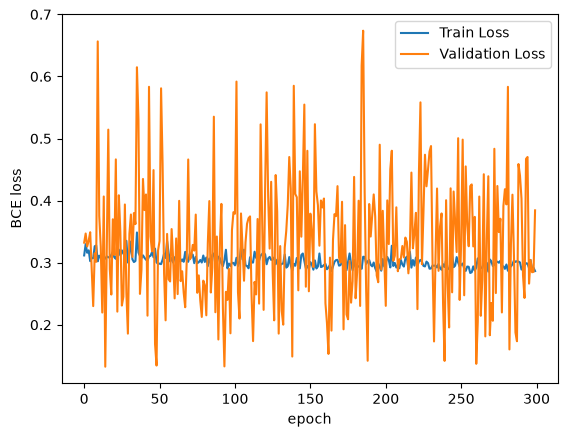

In [ ]:
# implement your solution BELOW

loss_fn = nn.BCELoss()
learning_rate = 0.001
N_EPOCH = 300
patience = 30
optimizer = torch.optim.Adam(bincl_model.parameters(), lr=learning_rate)

best_loss = np.inf
worst_epoch = 0
best_model = None

train_loss = []
train_acc = []

val_loss = []
val_acc = []

for i in range(N_EPOCH):
    t_batch_loss = []
    v_batch_loss = []
    
    for xb, yb in dataloader_bincl_train:
        bincl_model.train()
        
        # Forward
        predictions = bincl_model(xb)
        loss = loss_fn(predictions, yb)
        t_batch_loss.append(loss.item())
        
        # Backward
        loss.backward()

        # Step
        optimizer.step()

        # Clear
        optimizer.zero_grad()

                
    train_loss.append(np.mean(t_batch_loss))
    
    for xb, yb in dataloader_bincl_val:
        bincl_model.eval()
        
        loss = loss_fn(bincl_model(xb), yb)
        v_batch_loss.append(loss.item())
        
        if loss < best_loss:
                best_loss = loss
                worst_epoch = 0
                best_model = copy.deepcopy(bincl_model.state_dict())
        
                print(f"""({i}) Loss: {t_batch_loss[-1]}""", )
        else:
            worst_epoch += 1
        
            if worst_epoch >= patience:
                print("interrupted no patience left")
                    
                break

    val_loss.append(np.mean(t_batch_loss))
        

# Restore the best model
bincl_model.load_state_dict(best_model)      


test_loss = []
test_loss_b = []

with torch.no_grad():
    for xb, yb in dataloader_bincl_val:
        bincl_model.eval()
        
        loss = loss_fn(bincl_model(xb), yb)
        test_loss_b.append(loss.item())

    test_loss.append(np.mean(t_batch_loss))


test_bce = np.mean(test_loss).item()

plt.figure()
plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel('epoch')
plt.ylabel('BCE loss')
plt.legend()

# implement your solution ABOVE

tester.test('bincl_model_learning', test_bce, test_acc)

## **H**: Printing the least confidently predicted sample items - 3 points

Print the five orange juices from the test set for which the neural network's prediction was the least confident. In other words, we are interested in those five orange juices for which the predicted probability was the closest to exactly 0.5. Note that this time we do not care whether the predictions were correct (that is, whether they ended up on the correct side of the 0.5 threshold), only how close they were to the decision boundary. Print all **input variable values, the predicted probability, and the true label** for these orange juices as well.

**Example:** a predicted probability of 0.4 is less confident than 0.7, but 0.55 is even less confident than both.

**Example output:** (it is not a problem if the formatting is not particularly neat)

```
Least confident predictions:
   #0: [11.175     3.253      9.019      2.016      183.086    0.889      2.117      0.264      0.         0.         5.095     ] -> pred: 0.50014126 v. true: 0.0
   #1: [6.3490e+00 3.7130e+00 1.0976e+01 1.6750e+00 1.8213e+02 7.5300e-01 1.9150e+00 5.1000e-01 4.6000e-02 2.5799e+01 0.0000e+00] -> pred: 0.49956003 v. true: 0.0
   #2: [1.0571e+01 3.6480e+00 8.8110e+00 1.7840e+00 1.8259e+02 7.0000e-01 1.2060e+00 4.6600e-01 9.0000e-03 6.7670e+00 0.0000e+00] -> pred: 0.49840668 v. true: 0.0
   #3: [8.864      3.466      10.033     1.88       205.452    0.516      2.058      0.805      0.         0.         23.589    ] -> pred: 0.49829003 v. true: 0.0
   #4: [5.7570e+00 3.6480e+00 7.2230e+00 1.7620e+00 1.7771e+02 7.3900e-011.41100e+00 5.6300e-01 1.5000e-02 0.0000e+00 1.9920e+00] -> pred: 0.50215644 v. true: 0.0
```

Full score is given only if you find these five orange juices **using shared, vectorized operations**. The printing itself may, of course, be done with a loop.


In [ ]:
# implement your solution BELOW (No automatic tests for this task)










## **I**: Histogram of predicted probabilities by true category - 3 points

In this last task, we analyze the distribution of the probabilities predicted by the network separately for budget orange juices and premium orange juices.

Separate the orange juices from the test set according to their true label categories, then **plot a histogram for each of the two categories showing the distribution of the probabilities predicted by the neural network.** In the histogram, the data points are grouped into bins according to the corresponding predicted probabilities (horizontal axis). The number of elements in each bin is indicated by the columns along the vertical axis. Choose an appropriate bin size! 
To create histograms, we recommend (but do not require) using the `matplotlib.pyplot.hist()` function.

**An example plot:**

<img src="zh_files/taskI_figure.png" style="display:inline-block" width='60%'>


In [ ]:
# implement your solution BELOW (No automatic tests for this task)








